In [ ]:
##

In [1]:
from sem2 import sem2
from engression.loss_func import energy_loss, energy_loss_two_sample
from Amari_error import Amari_error
import torch
from torch import nn
import scipy.stats as stats
import pandas as pd
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

In [3]:
def generate_data(n_samples=5000,A_true=None):
    # S1_true= stats.norm(loc=0, scale=1).rvs(size=n_samples)
    # S2_true= stats.uniform(loc=-2, scale=2).rvs(size=n_samples)
    S3_true=stats.expon(scale=1).rvs(size=n_samples)
    S4_true= stats.gamma(a=2, scale=1).rvs(size=n_samples)
    S5_true=stats.beta(a=2, b=5).rvs(size=n_samples)
    #S6_true=stats.chi2(df=5).rvs(size=n_samples)
    # S7_true=stats.t(df=10).rvs(size=n_samples)
    S_true = np.vstack([S3_true,S4_true,S5_true])
    X=A_true @ S_true
    return X.T

def generate_mixing_matrix(n,d):
    sigma = np.random.uniform(1, d, n-2) 
    sigma = np.concatenate([sigma, [1, d]])  
    np.random.shuffle(sigma) 
    Sigma = np.diag(sigma)
    R1 = np.random.randn(n, n)
    U, _ = np.linalg.qr(R1)
    R2 = np.random.randn(n, n)
    V, _ = np.linalg.qr(R2)
    A = U @ Sigma @ V.T
    return A

In [5]:
A_true = generate_mixing_matrix(3, 5) 
X = generate_data(n_samples=5000, A_true=A_true)
var_names = [f'x{i+1}' for i in range(3)]
X_df = pd.DataFrame(X, columns=var_names)
dataset = torch.tensor(X_df.to_numpy())

In [7]:
fastica = FastICA(n_components=3)
fastica.fit(X) 
A_init = torch.tensor(fastica.mixing_, dtype=torch.float32)
Amari_error(A_init,A_true)

0.027737157280293617

In [9]:
model_formula_X = "x1 <- s1 + s2+s3; x2 <- s1 + s2+s3; x3 <- s1 + s2+s3"
model_formula_S = "s1 ~ expon(scale=1); s2 ~ gamma(a=2, scale=1); s3 ~ beta(a=2, b=5);"
model_formula = model_formula_S + model_formula_X
model = sem2(model_formula, use_bias=False)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = sem2(model_formula, use_bias=False)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
niter = 5000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(x.size(0) * 8)[:, observed_index]
    loss, s1, s2 = energy_loss(x, sample)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

final_coef_matrix = np.zeros([len(observed_var), 3])  # 形状 [4, 4]
for j, node in enumerate(observed_var):
    if model.layer[node] is not None:
        weights = model.layer[node].weight.detach().cpu().numpy()  # [1, 4]
        final_coef_matrix[j, :] = weights.flatten()  # 存入第 j 行
        
print(Amari_error(final_coef_matrix,A_true))

X_01=generate_data(n_samples=25000, A_true=A_true)
X_hat=generate_data(n_samples=25000, A_true=final_coef_matrix)
loss_0, s1_0, s2_0 = energy_loss(dataset, torch.as_tensor(X_01))
loss_1, s1_1, s2_1 = energy_loss(dataset, torch.as_tensor(X_hat))
print(loss_0, s1_0, s2_0)
print(loss_1, s1_1, s2_1)

Iter 1 | loss: 8.4045, s1: 8.9433, s2: 1.0777
Iter 1000 | loss: 3.4594, s1: 6.4377, s2: 5.9567
Iter 2000 | loss: 3.3856, s1: 6.6731, s2: 6.5750
Iter 3000 | loss: 3.4110, s1: 6.7721, s2: 6.7222
Iter 4000 | loss: 3.4277, s1: 6.8246, s2: 6.7937
Iter 5000 | loss: 3.3944, s1: 6.7839, s2: 6.7790
0.598712474415089
tensor(3.3919, dtype=torch.float64) tensor(6.8402, dtype=torch.float64) tensor(6.8965, dtype=torch.float64)
tensor(3.4081, dtype=torch.float64) tensor(6.8480, dtype=torch.float64) tensor(6.8798, dtype=torch.float64)


In [11]:
A_true

array([[ 2.82438064,  0.88342132, -1.29967133],
       [-3.06036045, -0.32132566, -2.88066823],
       [ 1.42112546,  2.63640943, -2.97556506]])

In [15]:
final_coef_matrix

array([[ 1.12324297,  1.88971221, -2.67560387],
       [-0.14893882, -2.03897858, -0.60682744],
       [ 3.84886622,  1.182796  , -1.07038748]])

In [17]:
A_true[0]

array([ 2.82438064,  0.88342132, -1.29967133])

In [77]:
X1_true=generate_data(n_samples=5000, A_true=A_true[0])
X1_hat=generate_data(n_samples=5000, A_true=final_coef_matrix[0])

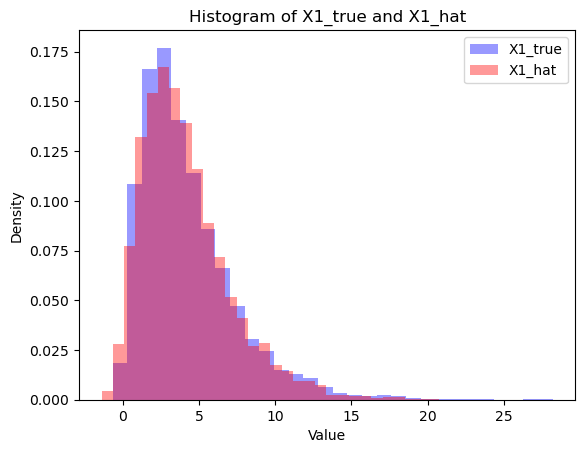

In [81]:
plt.hist(X1_true, bins=30, color='blue', alpha=0.4, label='X1_true', density=True)
plt.hist(X1_hat, bins=30, color='red', alpha=0.4, label='X1_hat', density=True)


plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Histogram of X1_true and X1_hat')
plt.legend()

plt.show()

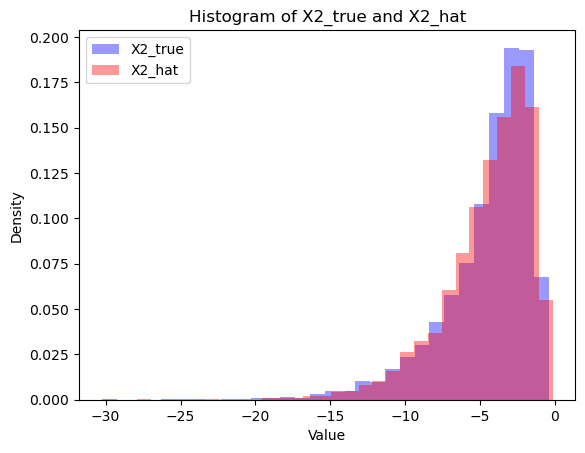

In [205]:
X2_true=generate_data(n_samples=5000, A_true=A_true[1])
X2_hat=generate_data(n_samples=5000, A_true=final_coef_matrix[1])
plt.hist(X2_true, bins=30, color='blue', alpha=0.4, label='X2_true', density=True)
plt.hist(X2_hat, bins=30, color='red', alpha=0.4, label='X2_hat', density=True)


plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Histogram of X2_true and X2_hat')
plt.legend()

plt.show()

In [211]:
X3_true=generate_data(n_samples=5000, A_true=A_true[2])
X3_hat=generate_data(n_samples=5000, A_true=final_coef_matrix[2])

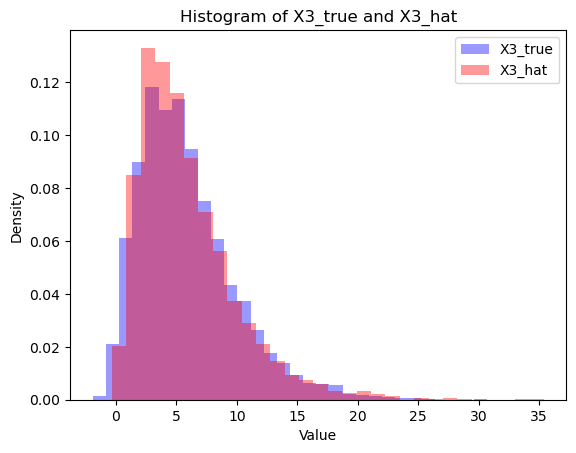

In [213]:
plt.hist(X3_true, bins=30, color='blue', alpha=0.4, label='X3_true', density=True)
plt.hist(X3_hat, bins=30, color='red', alpha=0.4, label='X3_hat', density=True)


plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Histogram of X3_true and X3_hat')
plt.legend()

plt.show()

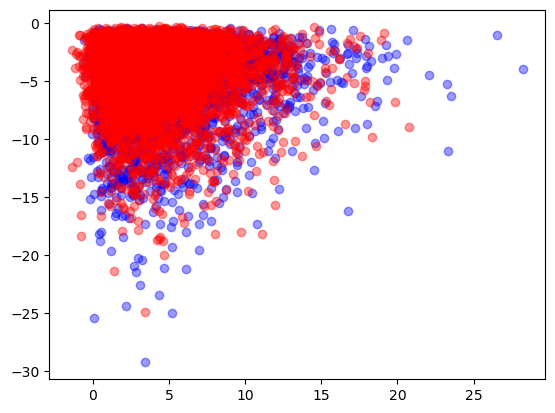

In [215]:
plt.scatter(X1_true, X2_true, color = "blue", alpha = 0.4)
plt.scatter(X1_hat, X2_hat, color = "red", alpha = 0.4)

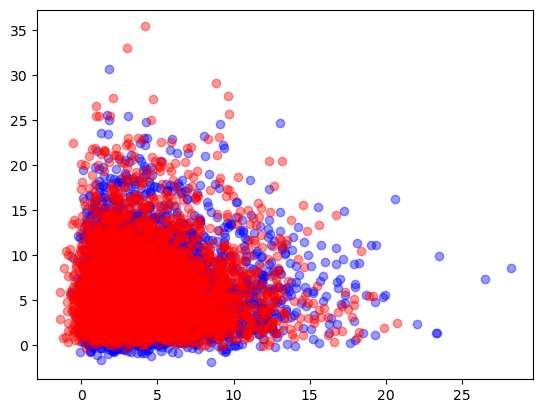

In [217]:
plt.scatter(X1_true, X3_true, color = "blue", alpha = 0.4)
plt.scatter(X1_hat, X3_hat, color = "red", alpha = 0.4)

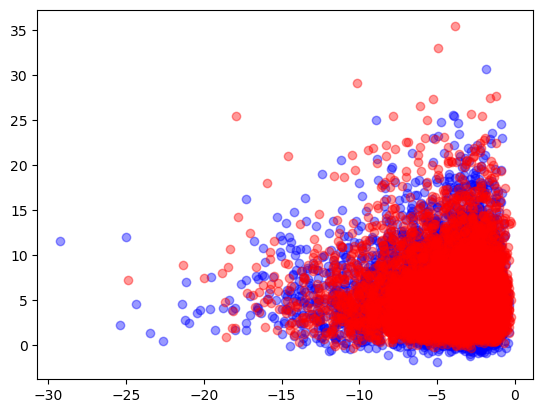

In [219]:
plt.scatter(X2_true, X3_true, color = "blue", alpha = 0.4)
plt.scatter(X2_hat, X3_hat, color = "red", alpha = 0.4)